In [4]:
from multi_func import *
import torch
from torch import nn, optim
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
import os

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

In [5]:
bs = 32
LR = 1e-3
EPOCH = 5
cri = nn.CrossEntropyLoss()
new_model_train = True
model_type = "MLP"
dataset = "MNIST"
os.makedirs("result", exist_ok=True)
save_model_path = f"result/{model_type}_{dataset}.pt"

In [ ]:
trans = transforms.ToTensor()
trds = datasets.MNIST(root="data", train=True, download=False, transform=trans)
teds = datasets.MNIST(root="data", train=False, download=False, transform=trans)
trdl = DataLoader(trds, batch_size=bs, shuffle=True)
tedl = DataLoader(teds, batch_size=bs, shuffle=False)

In [7]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Sequential(
            nn.Linear(28 * 28, 30), nn.BatchNorm1d(30), nn.ReLU(), nn.Linear(30, 10)
        )

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        x = self.linear(x)
        return x


class MLPd(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Sequential(
            nn.Linear(28 * 28, 30),
            nn.BatchNorm1d(30),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(30, 10),
        )

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        x = self.linear(x)
        return x

In [8]:
model=globals()['MLP']().to(DEVICE)

epoch: 1, train loss: 0.402
epoch: 2, train loss: 0.206
epoch: 3, train loss: 0.168
epoch: 4, train loss: 0.144
epoch: 5, train loss: 0.133


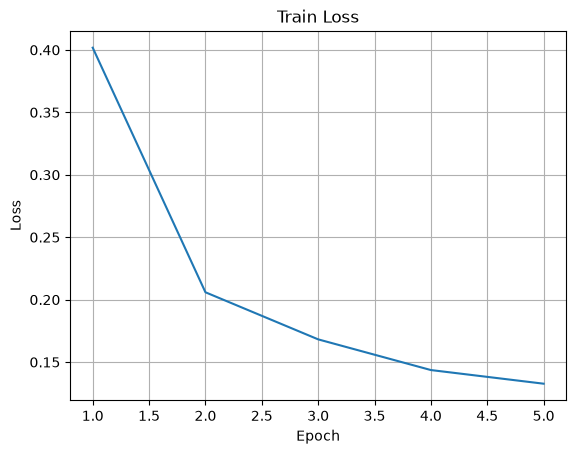

In [9]:
if new_model_train:
    op = optim.Adam(model.parameters(), lr=LR)
    lh = Train(model, trdl, cri, op, EPOCH)
    torch.save(model, save_model_path)
    plt.plot(range(1, EPOCH + 1), lh)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Train Loss")
    plt.grid()

In [10]:
load_model = torch.load(save_model_path, map_location=DEVICE, weights_only=False)

In [11]:
Test(load_model, tedl)
print(count_params(load_model))

test accuracy: 9634/10000 96.3%
23920


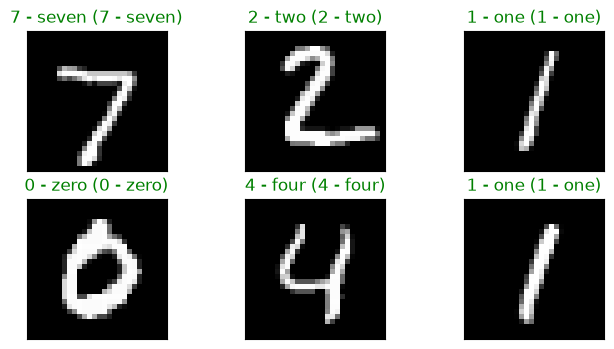

In [12]:
Test_plot(load_model, tedl)